In [ ]:
# Complete coding drsulm

# https://www.kaggle.com/datasets/tanishksharma9905/global-economic-indicators-20102025

In [ ]:
# STEP 1: Install necessary packages (only once in Colab)
!pip install -q tensorflow pandas scikit-learn matplotlib

    What it does:
    This line installs Python libraries in a Google Colab notebook environment using pip, the Python package manager.

    Breakdown:
    Component	Purpose
    !	Tells Colab to run a shell command (like in a terminal).


    pip install	Installs Python packages.
    
    
    -q	Quiet mode: suppresses detailed output, so it’s cleaner.
    
    
    tensorflow	Main library used to build and train neural networks.
    
    
    pandas	For working with dataframes and CSV files (like Excel tables).
    
    
    scikit-learn	For data preprocessing, train-test splits, and ML tools.
    
    
    matplotlib	To plot training history, graphs, and visualizations.

    When to use it:
    You only need to run it once per Colab session (or if you restart the runtime).

    These libraries are sometimes preinstalled, but including this ensures everything works smoothly.

In [ ]:
# STEP 2: Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

    import pandas as pd
    Purpose: Loads the Pandas library for data manipulation.

    Use:

    Reading CSV files.

    Handling datasets in table format (DataFrames).

    Cleaning and filtering data.

    Example: df = pd.read_csv('data.csv')


---



    import numpy as np
    Purpose: Loads NumPy, the core library for numerical operations.

    Use:

    Works with arrays and numerical computations.

    Often used under the hood in Pandas, TensorFlow, etc.

    Example: np.array([1, 2, 3])
___

    import matplotlib.pyplot as plt
    Purpose: Imports Matplotlib, a plotting library.

    Use:

    To visualize model training, such as loss and accuracy curves.

    To explore and understand data patterns.

    Example: plt.plot(history.history['loss'])
___
    from sklearn.model_selection import train_test_split
    Purpose: From Scikit-learn, used to split data into training and testing sets.

    Use:

    Ensures your model is evaluated on unseen data.

    Prevents overfitting by separating part of your data for validation/testing.

    Example: X_train, X_test, y_train, y_test = train_test_split(...)
___
    from sklearn.preprocessing import StandardScaler
    Purpose: Also from Scikit-learn, this scales features so they have mean = 0 and std = 1.

    Use:

    Neural networks learn faster and more accurately when input data is standardized.

    Prevents features with large values (like GDP) from dominating smaller ones (like interest rate).

    Example: X_scaled = scaler.fit_transform(X)
___
    from tensorflow.keras.models import Sequential
    Purpose: Imports the Sequential model API from Keras (inside TensorFlow).

    Use:

    This is how you define a linear stack of neural network layers.

    It's the simplest way to build a model: input → hidden layers → output.

    Example: model = Sequential()
___
    from tensorflow.keras.layers import Dense
    
    Purpose: Imports the Dense layer, a fully connected neural network layer.

    Use:

    Adds layers to the neural network.

    You define how many neurons, and what activation function to use.

    Example: model.add(Dense(64, activation='relu'))



In [ ]:
# STEP 3: Load the dataset (replace with actual file path if on Kaggle or Colab Drive)


df = pd.read_csv("/content/world_bank_data_2025.csv")  # Replace with actual filename

In [ ]:
# STEP 4: Clean column names and preview
df.columns = df.columns.str.strip()
print("Columns:", df.columns)

Columns: Index(['country_name', 'country_id', 'year', 'Inflation (CPI %)',
       'GDP (Current USD)', 'GDP per Capita (Current USD)',
       'Unemployment Rate (%)', 'Interest Rate (Real, %)',
       'Inflation (GDP Deflator, %)', 'GDP Growth (% Annual)',
       'Current Account Balance (% GDP)', 'Government Expense (% of GDP)',
       'Government Revenue (% of GDP)', 'Tax Revenue (% of GDP)',
       'Gross National Income (USD)', 'Public Debt (% of GDP)'],
      dtype='object')


In [ ]:

# STEP 5: Filter data for a specific country (India as an example)
india = df[df['country_name'] == 'India'].dropna()

    df['country_name'] == 'India'
    This creates a Boolean mask (a series of True/False values).

    It checks every row in the column 'country_name' and returns True only if the country is India.

    Example output:

    graphql
    Copy
    Edit
    0     False
    1     False
    2      True
    3      True
___
    df[ ... ]
    This applies the Boolean mask to the original DataFrame.

    It returns only the rows where the mask is True, i.e., only rows where country_name == 'India'.
___
    .dropna()
    This removes any rows that contain missing values (NaN) in any column.

    This ensures the neural network gets clean, complete data — which is essential for training.

In [ ]:
# STEP 6: Define features (X) and target (y)
X = india[[
    'Inflation (CPI %)',
    'Unemployment Rate (%)',
    'Interest Rate (Real, %)',
    'Current Account Balance (% GDP)'
]]

y = india['GDP Growth (% Annual)']

In [ ]:
# STEP 7: Normalize features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

    StandardScaler()
    Comes from sklearn.preprocessing.

    It standardizes (normalizes) your data.

    It removes the mean and scales to unit variance, i.e.:

    𝑋
    scaled
    =
    𝑋
    −
    𝜇
    𝜎
    X
    scaled
    ​
    =
    σ
    X−μ
    ​
    
    Where:

    𝜇
    μ is the mean of the feature

    𝜎
    σ is the standard deviation
    ___
    scaler.fit_transform(X)
    fit() computes the mean and std for each feature (i.e., each column).

    transform() then applies the formula above.

    Together, fit_transform():

    Learns how to scale the features from the training data.

    Returns a new scaled version of X.
    ___
    Why Normalization Is Crucial:
    Problem	Without Normalization	With Normalization
    Feature Scale	Some features (like GDP) may have huge values (billions), others (like interest rates) may be tiny	All features have a mean of 0 and a standard deviation of 1
    Neural Network Training	Training becomes unstable, gradient updates are skewed	Training is faster, more stable, and converges better


    Fairness	Features with larger ranges dominate	Each feature contributes equally

    Example:
    Suppose your X looks like this:

    Inflation	Unemployment	Investment
    4.5	6.2	2000000
    5.0	6.5	2100000

    After scaling with StandardScaler, you'll get:

    Scaled_Inflation	Scaled_Unemployment	Scaled_Investment
    -1.0	-1.0	-1.0
    +1.0	+1.0	+1.0

    Result:
    After this step, your input data (X_scaled) is ready to be fed into a neural network for training.

In [ ]:
# STEP 8: Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, random_state=42
)

In [ ]:
# STEP 9: Build the neural network
model = Sequential([
    Dense(16, activation='relu', input_shape=(X_train.shape[1],)),
    Dense(8, activation='relu'),
    Dense(1)  # Output layer for regression
])

/usr/local/lib/python3.11/dist-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [ ]:

# STEP 10: Compile the model
model.compile(optimizer='adam', loss='mean_squared_error', metrics=['mae'])

In [ ]:
# STEP 11: Train the model
history = model.fit(X_train, y_train, epochs=100, batch_size=8, validation_split=0.2)

Epoch 1/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step - loss: 55.0133 - mae: 7.3244 - val_loss: 58.3955 - val_mae: 7.5734
Epoch 2/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 174ms/step - loss: 54.7419 - mae: 7.3059 - val_loss: 58.1864 - val_mae: 7.5581
Epoch 3/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 91ms/step - loss: 54.4742 - mae: 7.2877 - val_loss: 57.9635 - val_mae: 7.5419
Epoch 4/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 142ms/step - loss: 54.2092 - mae: 7.2697 - val_loss: 57.7365 - val_mae: 7.5254
Epoch 5/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 135ms/step - loss: 53.9449 - mae: 7.2516 - val_loss: 57.5076 - val_mae: 7.5087
Epoch 6/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 130ms/step - loss: 53.6814 - mae: 7.2336 - val_loss: 57.2777 - val_mae: 7.4920
Epoch 7/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 88ms/step - loss: 53.4191 - mae: 7.2155 - val_loss: 57.0476 - val_mae: 7.4752
Epoch 8/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 89ms/step - loss: 53.1595 - mae: 7.1975 - val_loss: 56.8223 - val_mae: 7.4586
Epoch 9/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 131ms/step - l

In [ ]:
# STEP 12: Evaluate on test data
loss, mae = model.evaluate(X_test, y_test)
print(f"\nTest MAE: {mae:.2f}")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - loss: 25.9781 - mae: 4.7594

Test MAE: 4.76


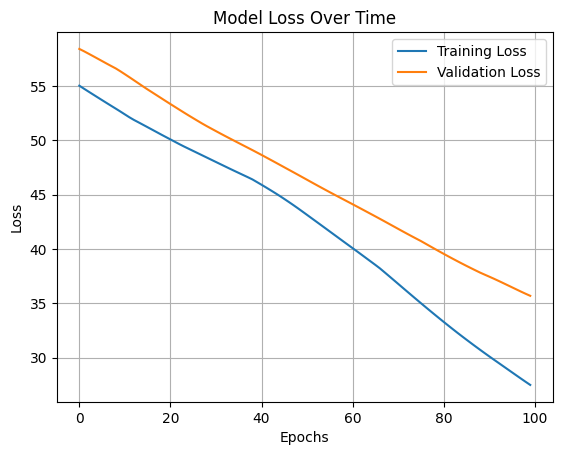

In [ ]:
# STEP 13: Plot training history
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Model Loss Over Time")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
# STEP: User input, scaling, prediction — all in one

# Define feature names in the order used during training
feature_names = [
    'Inflation (CPI %)',
    'Unemployment Rate (%)',
    'Current Account Balance (% GDP)',
    'Public Debt (% of GDP)'
]

# Step 1: Collect user input for all features
print("Please enter the following economic indicators:")

user_input = []
for feature in feature_names:
    value = float(input(f"{feature}: "))
    user_input.append(value)

# Convert to 2D array as model expects batch input
user_data = [user_input]

# Step 2: Scale the user input using the same scaler used in training
user_data_scaled = scaler.transform(user_data)

# Step 3: Make prediction using the trained model
prediction = model.predict(user_data_scaled)

# Step 4: Output the result
print("\n📈 Predicted GDP Growth: {:.2f}%".format(prediction[0][0]))



Please enter the following economic indicators:
Inflation (CPI %): 5
Unemployment Rate (%): 6
Current Account Balance (% GDP): 5
Public Debt (% of GDP): 5
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step

📈 Predicted GDP Growth: 3.24%


/usr/local/lib/python3.11/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
